*This notebook was developed by Kabelo Tsiane for the DESC CL_Cosmo_Pipeline team.*

# This notebook presents the cluster pipeline outputs for stacked $\Delta\Sigma$ and $g_t$ profiles on Rubin Data Preview 2 (DP2).

It is meant to be run independently. You must run the pipeline from the terminal first, see below.

The pipeline goes from the cluster catalog (a CSV file) and a DP2 shear catalog to stacked cluster lensing profiles, in one run. There is one pipeline per shear catalog; you choose the shear catalog by choosing which pipeline to run. Section 5 compares the profiles from the different shear catalogs.

___

In [1]:
import os
import sys
from pprint import pprint

import ceci
import h5py

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pickle
import yaml
from IPython.display import Image

Make sure to change your path in the next cell that leads to your TXPipe directory. The DP2 pipeline files are in `examples/dp2/Cluster_pipelines/`.

In [2]:
# user specific paths -- NERSC example
my_txpipe_dir = "/global/cfs/cdirs/m1727/kabelo/TXPipe"

os.chdir(my_txpipe_dir)

# TXPipe is used from its source directory, not installed
sys.path.insert(0, my_txpipe_dir)
import txpipe

___

# 1 - Launching the pipeline

There is one pipeline (and one submission script) per DP2 shear catalog. Both catalogs come from the DESC data registry, and both are cut with the DESC wide-field metadetect mask (registry id 151, `rubin_dp2_wide_metadetect_mask` 0.2.0):

| shear catalog | registry id | pipeline file | submission script |
|---|---|---|---|
| Rubin metadetect | 137 | `examples/dp2/Cluster_pipelines/pipeline-dp2-CL-rubin-nersc.yml` | `examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub` |
| Sheldon (DESC) metadetect | 147 | `examples/dp2/Cluster_pipelines/pipeline-dp2-CL-sheldon-nersc.yml` | `examples/dp2/Cluster_pipelines/dp2-sheldon-nersc.sub` |

Everything else (the cluster catalog, the photo-z settings, the cluster bins and the profile settings) is the same for both, and lives in one config file, `config-dp2-CL.yml`.

As of 12 Oct 2026 these masks, and catalogs, are constantly changing. See guidance on [confluence](https://confluence.slac.stanford.edu/pages/viewpage.action?pageId=726185111&spaceKey=LSSTDESC&title=Data%2BPreview%2B2). 

In [3]:
shear_catalog = "rubin"   # or "sheldon": the shear catalog whose pipeline we look at in Sections 2-4
pipeline_dir = "examples/dp2/Cluster_pipelines"
pipeline_file = f"{pipeline_dir}/pipeline-dp2-CL-{shear_catalog}-nersc.yml"
submission_script = f"{pipeline_dir}/dp2-{shear_catalog}-nersc.sub"

## **Commands to run the pipeline from your TXPipe directory**
This will launch a job on a single NERSC CPU node to run the whole pipeline. After the first run, the output files exist, and later runs skip the stages that are already done (`resume: true`).

### If you are **on NERSC, you will run**:
```sbatch examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub```

or, for the other shear catalog:
```sbatch examples/dp2/Cluster_pipelines/dp2-sheldon-nersc.sub```

A run from scratch takes about 50 min of compute for Rubin and about 75 min for Sheldon (Oct 2026), most of it the photo-z stage `BPZliteEstimator`, which runs on every object in the cut shear catalog. Sheldon's catalog has about three times as many rows. The wait in the queue comes on top of that.

The outputs in `output_dir` are from the runs of 12 Oct 2026 (made with the same settings by step-by-step versions of these pipelines), so with `resume: true` a new submission only runs the stages whose outputs are missing.

You can look at the output of your submission in the file `slurm-xxx.out`, with xxx the number of your batch job. If you see *'Pipeline successful.  Joy is sparked.'* : congratulations, it worked!

Once the pipeline is run you can go directly to 4) to look at the results.

___

# 2 - Looking at the different pipeline files

### **Let's look at the submission script :**

In [4]:
! cat {submission_script}

#!/bin/bash
#SBATCH -A m1727
#SBATCH -C cpu
#SBATCH --qos=regular
#SBATCH --time=01:30:00
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=64
#SBATCH --cpus-per-task=2
# Full DP2 cluster-lensing pipeline for the rubin shear catalog. From the TXPipe directory:
#     sbatch examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub
# Expected run time from scratch: ~50 min (Oct 2026: ~35 min for the shear-catalog stages + ~12 min of profiles).
# resume: true in the pipeline file skips finished stages on reruns.

module load python
conda activate ./conda
ceci examples/dp2/Cluster_pipelines/pipeline-dp2-CL-rubin-nersc.yml


### **The submission script is specifying the pipeline yaml file. Let's look at it :**

- `site` and `launcher` say where and how the stages run. The `stages` list goes from the cluster catalog, through the shear catalog and the photo-z, to the profiles.
- `CLIngestClusterCSV` turns the cluster CSV file into the cluster catalog file that the cluster stages read (`txpipe/extensions/cluster_counts/ingest_csv.py`; the cosmoDC2 tutorials use `CLIngestRedmapper` instead).
- `TXIngestHealsparseMask` converts the registry mask into TXPipe's mask format, and `TXCutShearCatalog` keeps the objects inside it. `aliases` rename a stage's input or output: the cut stage reads the registry catalog as `full_shear_catalog` and writes the `shear_catalog` the later stages read.
- The cluster-shear stages run twice, once for $\Delta\Sigma$ and once for $g_t$. Each copy has its own `name` (which selects its section of the config file), and its `aliases` send its outputs to the `delta_sigma/` or `gt/` sub-directory of the output directory.
- `inputs` with an `id:` are looked up in the DESC data registry (this needs the `registry:` block).

In [5]:
! cat {pipeline_file}

# DP2 cluster-lensing pipeline for the RUBIN METADETECT shear catalog: from the
# cluster CSV file to stacked Delta Sigma and g_t profiles, in one ceci run.
#   cluster catalog: CSV -> TXPipe cluster file -> redshift/richness bins
#   shear catalog:   registry mask -> cut catalog -> source selection + calibration
#                    -> BPZ photo-z per source
#   profiles:        cluster-source pairs and stacked profiles, first Delta Sigma
#                    (Mpc), then the reduced tangential shear g_t (arcmin)
# From the TXPipe directory, submit with
#     sbatch examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub
# Settings live in config-dp2-CL.yml (shared by all shear catalogs).

#this step depends on where you run
#for NERSC
site:
    name: nersc-interactive

#all the following steps should not depend on where you run
launcher:
    name: mini
    interval: 3.0

modules: >
    txpipe
    txpipe.extensions.cluster_counts.bin_cluster
    txpipe.extensions.cluster_counts.sources_sele

### **The two shear catalogs' pipelines differ only in the shear catalog, its source selection and calibration, and the output directory:**

In [6]:
! diff {pipeline_dir}/pipeline-dp2-CL-rubin-nersc.yml {pipeline_dir}/pipeline-dp2-CL-sheldon-nersc.yml

1c1
< # DP2 cluster-lensing pipeline for the RUBIN METADETECT shear catalog: from the
---
> # DP2 cluster-lensing pipeline for the SHELDON (DESC) METADETECT shear catalog: from the
9c9
< #     sbatch examples/dp2/Cluster_pipelines/dp2-rubin-nersc.sub
---
> #     sbatch examples/dp2/Cluster_pipelines/dp2-sheldon-nersc.sub
10a11,15
> #
> # Differences from pipeline-dp2-CL-rubin-nersc.yml: the catalog has only the
> # ns/1p/1m (g1) shear steps, so TXPipe calibrates with R = R11 for both
> # components; the source selector applies E. Sheldon's cuts; and there is no
> # TXPSFMaps, because this catalog has no psf_g1/psf_g2 columns.
47c52
<   - name: TXSourceSelectorMetadetectDP2    # DP2 cuts; 2x2 response from 1p/1m/2p/2m
---
>   - name: TXSourceSelectorScalarMetadetectDP2    # E. Sheldon's cuts; R11 from 1p/1m for both components
55,56d59
<   - name: TXPSFMaps                # PSF ellipticity maps (diagnostic)
< 
100c103
< output_dir: /pscratch/sd/k/kabelo/dp2/outputs/rubin
---
> output_di

### **Each stage reads its options from the config file:**

Note `coordinate_system: euclidean` in the cluster-shear stages. The DP2 metadetect shears are given in the image-pixel frame, whose $g_2$ has the opposite sign to the sky frame; with TXPipe's default (`celestial`) the tangential shear averages to zero around every cluster.

In [7]:
! cat {pipeline_dir}/config-dp2-CL.yml

# Config for the full DP2 cluster-lensing pipelines (pipeline-dp2-CL-<catalog>-nersc.yml).
# One config for every shear catalog: the settings that must match between catalogs
# for a fair comparison (BPZ, cluster binning, profiles) are written once, and each
# catalog's source selector has its own section.
#
# The cluster-shear and profile stages run twice in each pipeline, once for
# Delta Sigma and once for the reduced tangential shear g_t, under the stage names
# below (ceci reads each stage's options from the section with its stage name).

CLIngestClusterCSV: {}   # CSV -> clusters HDF5 group; the column-name defaults match external_0723_x_dp2.csv

global:
    nside: 64
    chunk_rows: 1000000

TXIngestHealsparseMask: {}   # no options: reads the registry .hsp and rewrites it as a TXPipe mask file

TXSourceTomography:
    bands: [r, i, z] #used for selection
    source_zbin_edges: [0.1, 3.0] # this can be big, not doing cosmic shear

TXSourceSelectorMetadetectDP2:
    input_pz: fal

___

# 3 - Producing and looking at the pipeline diagram

Here we run the pipeline in "dry-run" mode, to check that it can run and to produce a pipeline diagram in png.

In [8]:
# Read the appropriate pipeline configuration, and ask for a flow-chart.
flowchart_file = f"CL_dp2_pipeline_{shear_catalog}.png"

pipeline_config = ceci.Pipeline.build_config(pipeline_file, flow_chart=flowchart_file, dry_run=True)

# Run the flow-chart pipeline
ceci.run_pipeline(pipeline_config);

The red ellipses are the stages, the yellow boxes the input files, and the blue boxes the output files. The cluster catalog (left) and the shear catalog (right) are processed separately and meet in the cluster-shear stages.

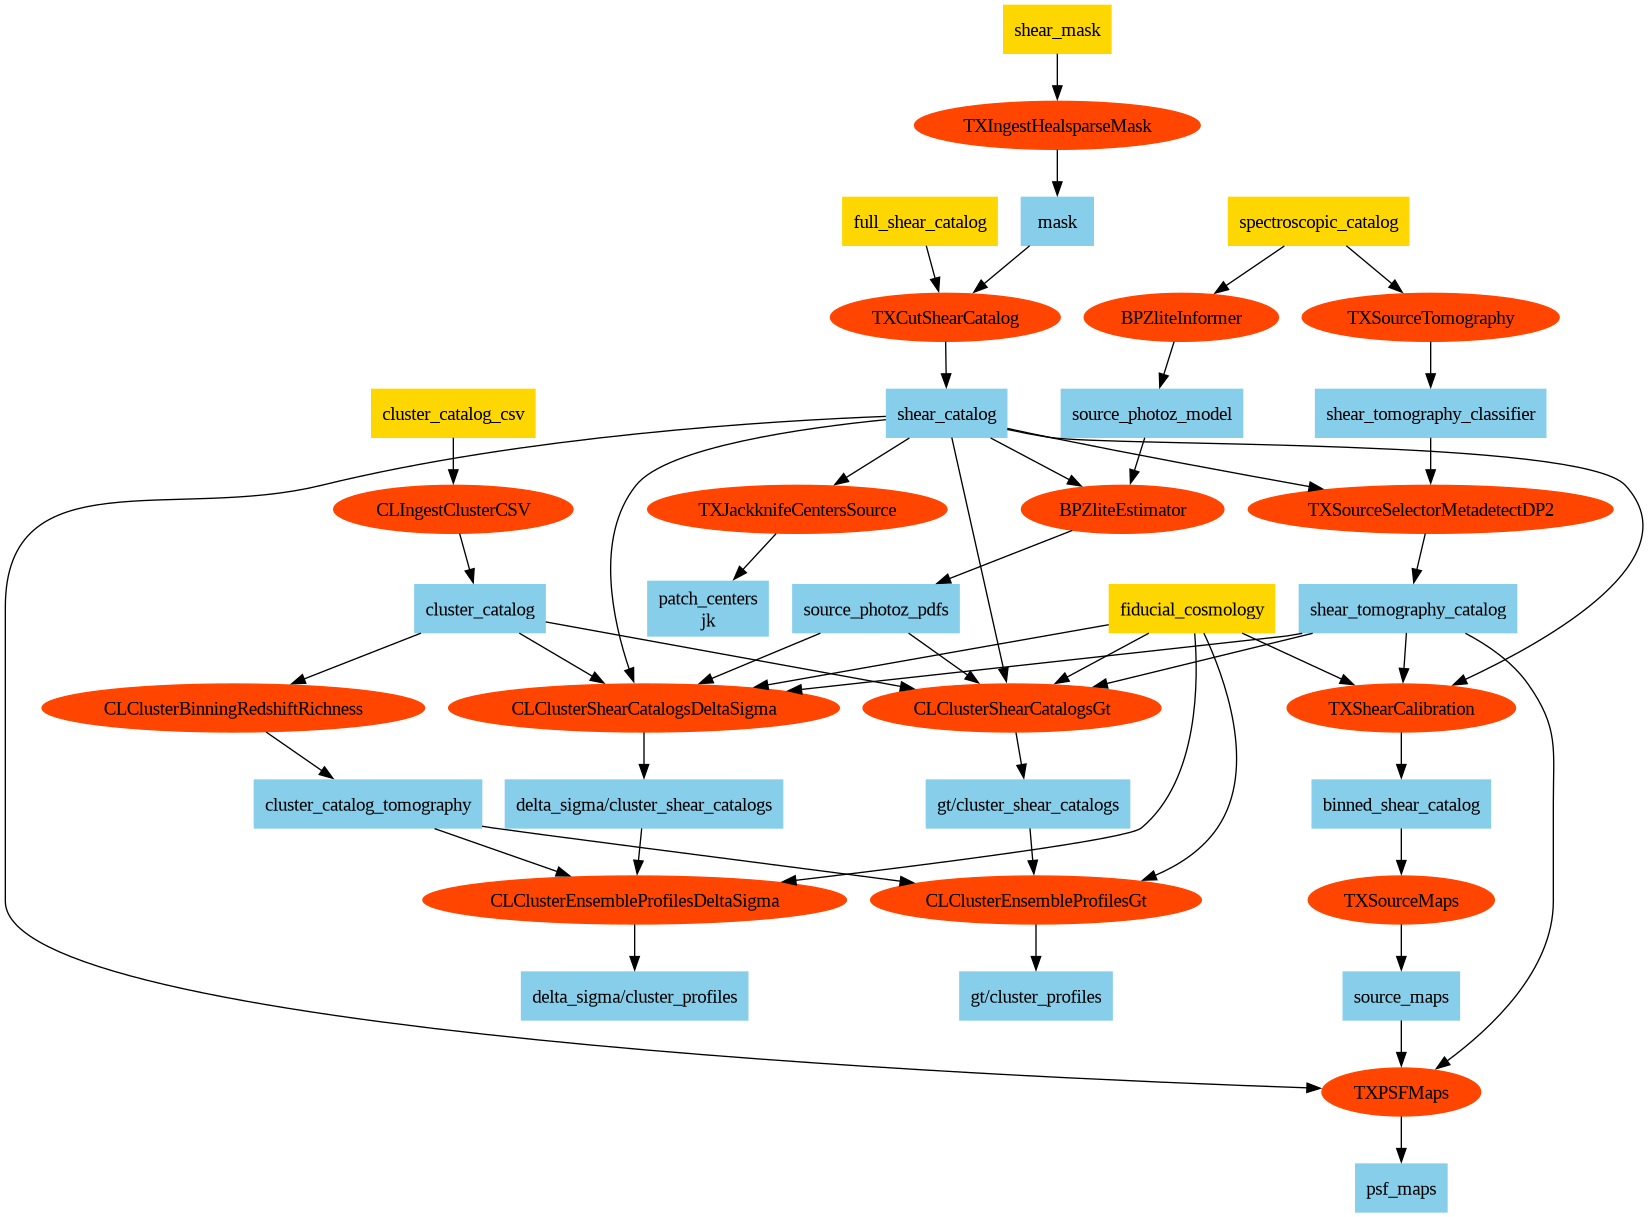

In [9]:
Image(flowchart_file)

___

# 4 - Opening and looking at the outputs

### **Open the pipeline file to load correct input/output file names**

In [10]:
with open(pipeline_file, "r") as file:
    pipeline_content = yaml.safe_load(file)
output_dir = pipeline_content["output_dir"]
print(output_dir)

/pscratch/sd/k/kabelo/dp2/outputs/rubin


### **Open the output**

There is one output file per profile type, in its own sub-directory of the output directory: `delta_sigma/cluster_profiles.pkl` and `gt/cluster_profiles.pkl`.

In [11]:
data = pickle.load(open(output_dir + "/delta_sigma/cluster_profiles.pkl", "rb"))
data_gt = pickle.load(open(output_dir + "/gt/cluster_profiles.pkl", "rb"))

In [12]:
data

{'bin_zbin_0_richbin_0': {'cluster_bin_edges': {'rich_max': np.float64(10.0),
   'rich_min': np.float64(5.0),
   'z_max': np.float64(0.4),
   'z_min': np.float64(0.2)},
  'n_cl': 0,
  'clmm_cluster_ensemble': None,
  'profile_type': 'delta_sigma'},
 'bin_zbin_0_richbin_1': {'cluster_bin_edges': {'rich_max': np.float64(100.0),
   'rich_min': np.float64(10.0),
   'z_max': np.float64(0.4),
   'z_min': np.float64(0.2)},
  'n_cl': 1040,
  'clmm_cluster_ensemble': <clmm.clusterensemble.ClusterEnsemble at 0x7f156af641a0>,
  'profile_type': 'delta_sigma'},
 'bin_zbin_1_richbin_0': {'cluster_bin_edges': {'rich_max': np.float64(10.0),
   'rich_min': np.float64(5.0),
   'z_max': np.float64(0.6),
   'z_min': np.float64(0.4)},
  'n_cl': 0,
  'clmm_cluster_ensemble': None,
  'profile_type': 'delta_sigma'},
 'bin_zbin_1_richbin_1': {'cluster_bin_edges': {'rich_max': np.float64(100.0),
   'rich_min': np.float64(10.0),
   'z_max': np.float64(0.6),
   'z_min': np.float64(0.4)},
  'n_cl': 1448,
  'clmm_c

The output is a dictionary containing a `CLMM` `ClusterEnsemble` object for each redshift/richness bin (`None` for a bin with no clusters).

### **Exploring the output**

In [13]:
example_bin = 'bin_zbin_0_richbin_1'

In [14]:
#This is the info for this bin
data[example_bin]

{'cluster_bin_edges': {'rich_max': np.float64(100.0),
  'rich_min': np.float64(10.0),
  'z_max': np.float64(0.4),
  'z_min': np.float64(0.2)},
 'n_cl': 1040,
 'clmm_cluster_ensemble': <clmm.clusterensemble.ClusterEnsemble at 0x7f156af641a0>,
 'profile_type': 'delta_sigma'}

In [15]:
#This shows the table with all cluster in this bin and their corresponding profiles
data[example_bin]['clmm_cluster_ensemble'].data

cluster_id,ra,dec,z,radius,tangential_comp,cross_comp,W_l
str5,float64,float64,float64,float64[6],float64[6],float64[6],float64[6]
31756,7.409679091427675,-6.633062898624641,0.2505527436733246,0.0 .. 3.629256278255649,0.0 .. 38565189736543.03,0.0 .. -6334211546752.522,0.0 .. 3.5892892825481765e-30
6787,3.92608087793794,-7.363509067465286,0.3324806988239288,0.0 .. 3.529209181879253,0.0 .. -608586059221643.8,0.0 .. -310356104687351.7,0.0 .. 3.864820171214418e-30
5661,5.006640049277415,-6.28576271137132,0.3304812014102936,0.0 .. 0.0,0.0 .. 0.0,0.0 .. 0.0,0.0 .. 0.0
3554,4.737604046302173,-6.147154613093692,0.2115606218576431,0.0 .. 4.415070471816415,0.0 .. -1075603578451113.1,0.0 .. -708029883625581.6,0.0 .. 5.279027270197617e-31
31405,0.3230647804595009,-5.329000002488484,0.2615756392478943,0.26174827413450386 .. 3.6223283935573956,1752436132872060.5 .. 44466594034287.9,2988504748103777.0 .. -21895276213092.99,6.995763924040753e-32 .. 1.2714634712332166e-28
16120,2.3689136613575346,-5.552242622154851,0.3526569902896881,0.0 .. 3.5280616104645244,0.0 .. 202430420203.146,0.0 .. 5182750700242.609,0.0 .. 6.537331044058124e-29
8676,4.253387794734972,-4.886457582943404,0.2743885815143585,0.29442110405982896 .. 3.7604886279619834,-590272115426097.5 .. 83468829554777.28,-1655983302157655.0 .. -34976279572239.957,1.0040735445508637e-31 .. 5.244707980068872e-29
8034,5.034808868947102,-4.744548281412531,0.3924670815467834,0.0 .. 3.5733889204771945,0.0 .. 148427851869873.06,0.0 .. -88369250871353.81,0.0 .. 2.7893275293432415e-30
24658,3.846121592920652,-4.131721292761234,0.381977379322052,0.22329968796010863 .. 3.680224357122386,255313836173517.25 .. -69068600397192.695,110550944949313.1 .. 55413053810645.125,2.151688697961116e-31 .. 3.2676481474207645e-29


In [16]:
#This shows the metadata of the ensemble stacked profiles
data[example_bin]['clmm_cluster_ensemble'].stacked_data.meta

GCMetaData([('cosmo',
             'CCLCosmology(H0=70.0, Omega_dm0=0.233, Omega_b0=0.046, Omega_k0=0.0)'),
            ('bin_units', 'mpc')])

In [17]:
#This shows the covariance for the ensemble stacked profiles
data[example_bin]['clmm_cluster_ensemble'].cov

{'tan_sc': None,
 'cross_sc': None,
 'tan_bs': None,
 'cross_bs': None,
 'tan_jk': array([[ 6.30065134e+26, -1.13020348e+25,  6.72768953e+25,
          1.46211415e+25, -3.33513828e+24, -2.40039465e+25],
        [-1.13020348e+25,  4.15226909e+26,  5.11862724e+25,
          9.31679663e+23, -1.29021952e+24,  8.34099821e+24],
        [ 6.72768953e+25,  5.11862724e+25,  1.80140636e+26,
          2.09652085e+24, -4.30265150e+23, -5.19968144e+23],
        [ 1.46211415e+25,  9.31679663e+23,  2.09652085e+24,
          3.47676077e+25,  1.69267707e+24,  5.59533181e+23],
        [-3.33513828e+24, -1.29021952e+24, -4.30265150e+23,
          1.69267707e+24,  1.38987156e+25,  2.55773616e+23],
        [-2.40039465e+25,  8.34099821e+24, -5.19968144e+23,
          5.59533181e+23,  2.55773616e+23,  8.58101610e+24]]),
 'cross_jk': array([[ 9.98176925e+26,  1.98466110e+26,  3.16925030e+25,
         -1.61964351e+25, -3.68681024e+25,  1.56500211e+25],
        [ 1.98466110e+26,  3.56206172e+26,  5.59629637e+2

### **Plot the output**

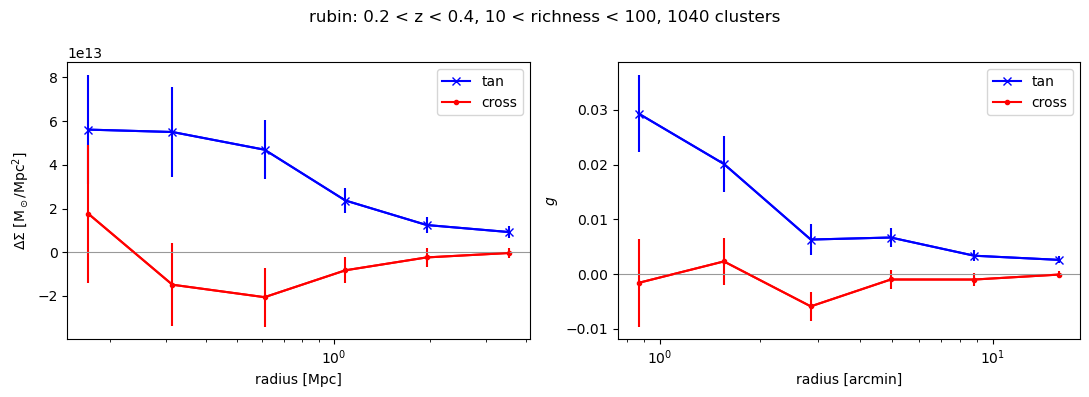

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, d, ylabel, xlabel in [(axes[0], data, '$\\Delta \\Sigma$ [M$_\\odot$/Mpc$^2$]', 'radius [Mpc]'),
                              (axes[1], data_gt, '$g$', 'radius [arcmin]')]:
    ens = d[example_bin]['clmm_cluster_ensemble']
    ax.semilogx(ens.stacked_data["radius"], ens.stacked_data["tangential_comp"], "bx-", label="tan")
    ax.semilogx(ens.stacked_data["radius"], ens.stacked_data["cross_comp"], "r.-", label="cross")
    ax.errorbar(ens.stacked_data["radius"], ens.stacked_data["tangential_comp"],
                yerr=ens.cov["tan_jk"].diagonal() ** 0.5, color="blue")
    ax.errorbar(ens.stacked_data["radius"], ens.stacked_data["cross_comp"],
                yerr=ens.cov["cross_jk"].diagonal() ** 0.5, color="red")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend()

edges = data[example_bin]['cluster_bin_edges']
fig.suptitle(f"{shear_catalog}: {edges['z_min']} < z < {edges['z_max']}, "
             f"{edges['rich_min']:.0f} < richness < {edges['rich_max']:.0f}, {data[example_bin]['n_cl']} clusters")
plt.tight_layout()

___

# 5 - Comparing the shear catalogs

Here we read the profiles of every shear catalog whose pipeline has been run, and overlay them for each redshift/richness bin. The clusters, the bins and the profile settings are identical, so the differences come from the shear catalogs: the shape measurement, the source selection and the calibration. Filled points are the tangential component; open points are the cross component, which should be consistent with zero.

In [19]:
colors = {"rubin": "#2a78d6", "sheldon": "#1baf7a"}
labels = {"rubin": "Rubin metadetect", "sheldon": "Sheldon metadetect"}

profiles = {}
for cat in ["rubin", "sheldon"]:
    with open(f"{pipeline_dir}/pipeline-dp2-CL-{cat}-nersc.yml") as file:
        out = yaml.safe_load(file)["output_dir"]
    if os.path.exists(f"{out}/gt/cluster_profiles.pkl"):
        profiles[cat] = {kind: pickle.load(open(f"{out}/{kind}/cluster_profiles.pkl", "rb")) for kind in ["delta_sigma", "gt"]}
print("shear catalogs with profiles:", list(profiles))

shear catalogs with profiles: ['rubin', 'sheldon']


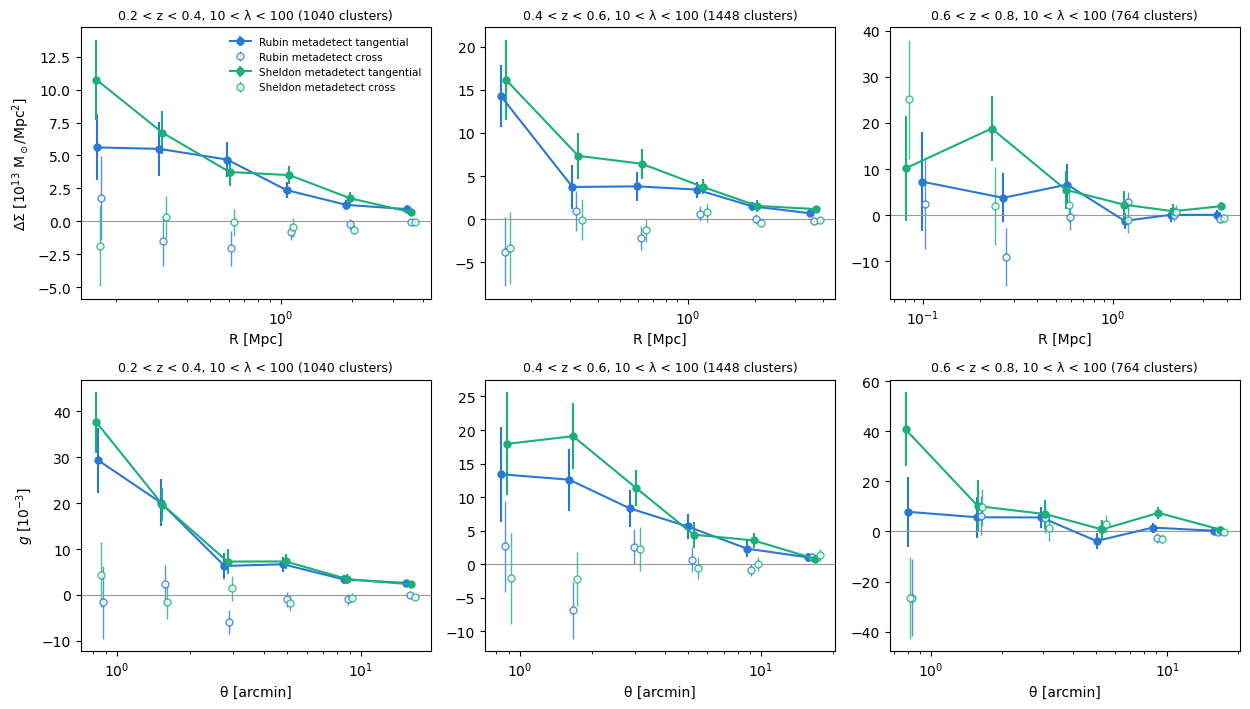

In [20]:
scale = {"delta_sigma": 1e13, "gt": 1e-3}
ylabel = {"delta_sigma": "$\\Delta\\Sigma$ [$10^{13}$ M$_\\odot$/Mpc$^2$]", "gt": "$g$ [$10^{-3}$]"}
xlabel = {"delta_sigma": "R [Mpc]", "gt": "θ [arcmin]"}

first = next(iter(profiles.values()))
bins = [b for b, e in first["gt"].items() if e["n_cl"] > 0]
fig, axes = plt.subplots(2, len(bins), figsize=(4.2 * len(bins), 7.2), squeeze=False)
for row, kind in zip(axes, ["delta_sigma", "gt"]):
    for ax, b in zip(row, bins):
        for (cat, prof), shift in zip(profiles.items(), [0.97, 1.03]):
            ens = prof[kind][b]["clmm_cluster_ensemble"]
            r = np.array(ens.stacked_data["radius"]) * shift
            ax.errorbar(r, np.array(ens.stacked_data["tangential_comp"]) / scale[kind],
                        yerr=np.sqrt(np.diag(ens.cov["tan_jk"])) / scale[kind],
                        fmt="o-", color=colors[cat], ms=5, lw=1.5, label=f"{labels[cat]} tangential")
            ax.errorbar(r * 1.04, np.array(ens.stacked_data["cross_comp"]) / scale[kind],
                        yerr=np.sqrt(np.diag(ens.cov["cross_jk"])) / scale[kind],
                        fmt="o", mfc="white", color=colors[cat], ms=5, lw=1, alpha=0.8, label=f"{labels[cat]} cross")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xscale("log")
        ax.set_xlabel(xlabel[kind])
        edges = first[kind][b]["cluster_bin_edges"]
        ax.set_title(f"{edges['z_min']:.1f} < z < {edges['z_max']:.1f}, {edges['rich_min']:.0f} < λ < {edges['rich_max']:.0f} "
                     f"({first[kind][b]['n_cl']} clusters)", fontsize=9)
    row[0].set_ylabel(ylabel[kind])
axes[0][0].legend(frameon=False, fontsize=7.5)
plt.tight_layout()